# Machine Learning Project

## Miopia Dataset

We start by importing the dependencies for the project and analyzing the data

In [136]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
import time
from collections import Counter
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, f1_score,
                             roc_curve, precision_recall_curve, confusion_matrix)
from xgboost import XGBClassifier

X_t = pd.read_csv("data/X_train.csv")
Y_t = pd.read_csv("data/Y_train.csv")
X_test= pd.read_csv("data/X_test.csv")

We now see the variables in the dataset

In [137]:
X_t.head()

,fecha,edad,sexo,origen antepasados (españa),origen antepasados (extranjeros),hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,...,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,2/11/20,22,Mujer,Asturias,NaN,0.0,0.0,4.0,4.0,40,...,0.238059,2.256667,0.564167,0.842300,0.905000,1.279863,1.810000,0.223333,0.160278,0.446667
1,2/17/20,23,Mujer,Navarra,NaN,5.0,2.0,2.0,9.0,20,...,2.585654,8.026667,2.006667,1.887316,3.620833,0.503224,7.241667,0.392500,0.102530,0.785000
2,3/10/20,22,Mujer,Bizkaia,NaN,2.0,3.0,8.0,13.0,30,...,0.431335,12.710000,3.177500,0.743668,3.152500,1.248043,6.305000,3.202500,0.314663,6.405000
3,2/26/20,22,Mujer,"Navarra, Extremadura, Cataluña, Aragón",España,0.0,2.0,13.0,15.0,54,...,0.626968,3.551667,0.887917,0.877145,1.003333,1.418928,2.006667,0.772500,0.491439,1.545000
4,2/19/20,23,Mujer,Toledo,NaN,3.0,0.0,0.0,3.0,56,...,1.269257,1.795000,0.448750,0.897500,0.897500,1.269257,1.795000,0.000000,0.000000,0.000000


In [138]:
Y_t.head()

,M,MM,Combo,DCombo
0,SI,SI,MM,MM
1,SI,NO,M,M1
2,NO,NO,C,C
3,NO,NO,C,C
4,NO,NO,C,C


In [139]:
list(X_t.columns)

['fecha',
 'edad',
 'sexo',
 'origen antepasados (españa)',
 'origen antepasados (extranjeros)',
 'hº deporte sem',
 'hº naturaleza sem',
 'hº ocio exteriores sem',
 'horas exterior sem',
 'hº estudiar sem',
 'hº ocio inter sem',
 'hº act.cerca sem',
 'horas interior sem',
 'Ratio Cerca/Lejos',
 'Exterior Mucho',
 'Interior Mcho',
 'fototipo',
 'Grupo fot',
 'familiar miope',
 'Familiar miope num.',
 'Familiar MM SI/NO',
 'familiar miope magno',
 'pat. Ret. Miop magna',
 'fumador',
 'toma sol',
 'protege sol',
 'disp.elec.antes dormir',
 'LA OD',
 'LA OS',
 'LA Media',
 'Querato OD',
 'Querato OD Eje2',
 'Querato OS',
 'Querato OS Eje 2',
 'OD-Total',
 'OD-Media',
 'OD-DS',
 'OS-Total',
 'OS-Media',
 'OS-DS',
 'CUVAF-Total',
 'CUVAF-Media',
 'CUVAF-DS',
 'Promedio Nasal',
 'DE Nasal',
 'Suma Nasal',
 'Promedio Temporal',
 'DE Temporal',
 'Suma Temporal']

We start by seeing that in the X_train part of the data there are some columns which can be dropped, since they can be considered redundant for the analysis we want to make.

First, the 'fecha' column is the date of the test. As this is a tracking value for the test itself it doesn't influence in the data and could even lead to some false correlations

We now try to see if we can discard some of the other columns

In [140]:
X_t['hº act.cerca sem'].head()


0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: hº act.cerca sem, dtype: float64

In [141]:
num_cols = X_t.select_dtypes('number').columns.tolist()
cont_cols = [c for c in num_cols if X_t[c].nunique() > 5]          # continuous-like
cat_cols = [c for c in X_t.columns if c not in cont_cols]          # categorical / binary / low-cardinality

# groups for later plots (keeps only columns that exist)
hours = [c for c in ['hº deporte sem', 'hº naturaleza sem', 'hº ocio exteriores sem',
                     'hº estudiar sem', 'hº ocio inter sem', 'horas exterior sem',
                     'horas interior sem', 'Ratio Cerca/Lejos'] if c in X_t]
biometry = [c for c in ['LA OD', 'LA OS', 'LA Media', 'Querato OD', 'Querato OS'] if c in X_t]

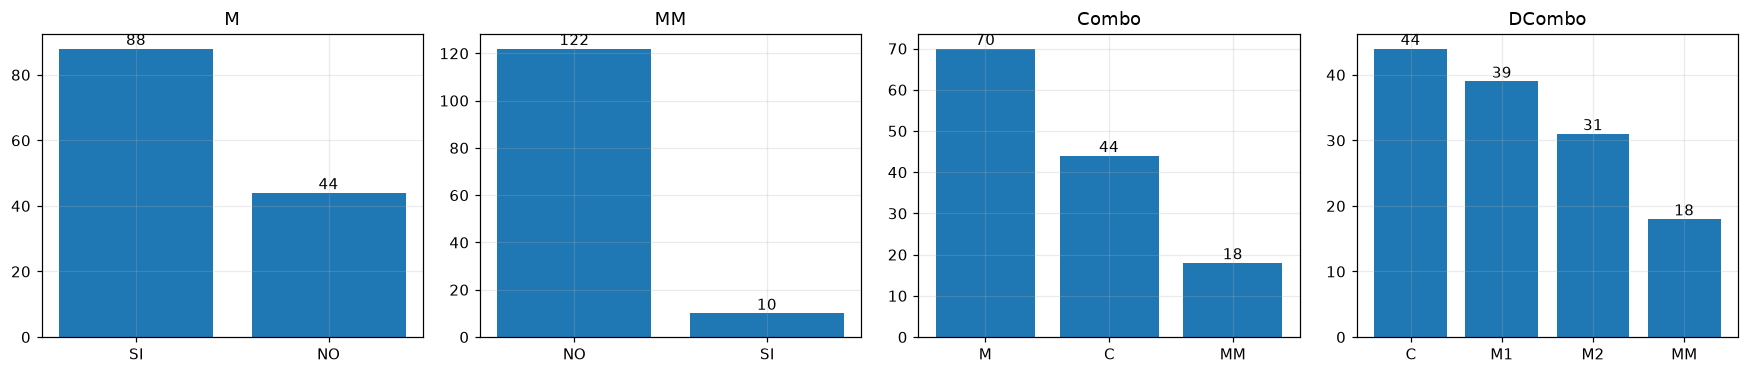

In [142]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, Y_t.columns):
    vc = Y_t[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values)
    for i, v in enumerate(vc.values):
        ax.text(i, v, v, ha='center', va='bottom')
    ax.set_title(col)
plt.tight_layout()
plt.show()

We see that the data for MM is skewed since there are a lot more negatives than positives

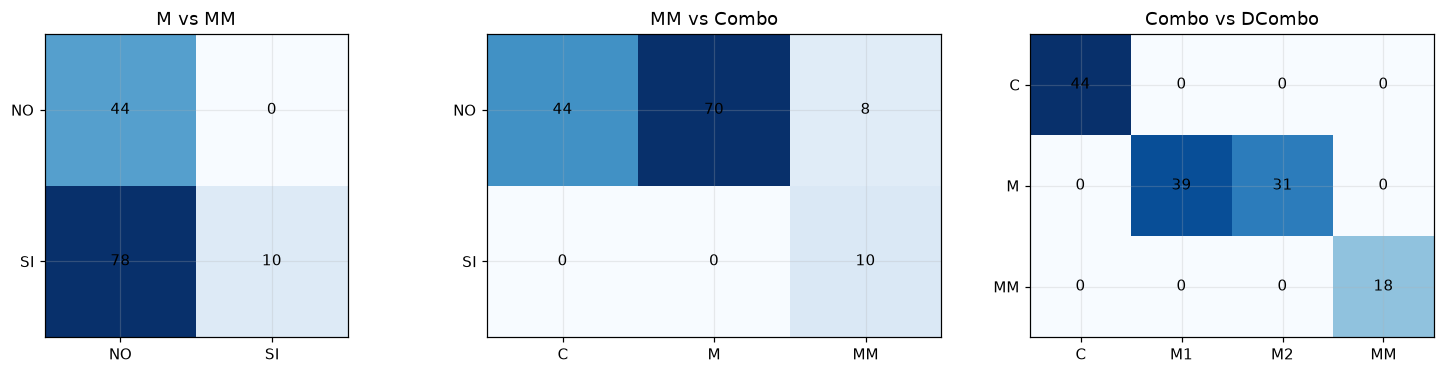

In [143]:
def heat(ct, ax, title):
    ax.imshow(ct.values, cmap='Blues')
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.values[i, j], ha='center', va='center')
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
heat(pd.crosstab(Y_t['M'], Y_t['MM']), axes[0], 'M vs MM')
heat(pd.crosstab(Y_t['MM'], Y_t['Combo']), axes[1], 'MM vs Combo')
heat(pd.crosstab(Y_t['Combo'], Y_t['DCombo']), axes[2], 'Combo vs DCombo')
plt.tight_layout()
plt.show()

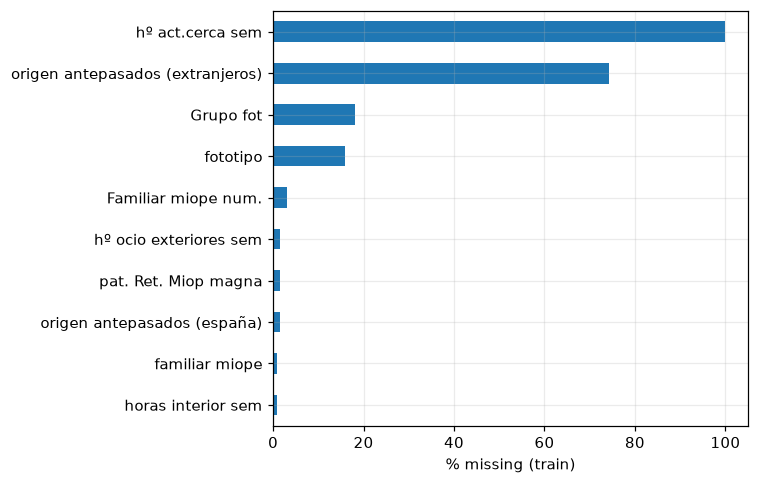

In [144]:
miss = (X_t.isna().mean() * 100).sort_values()
miss = miss[miss > 0]
ax = miss.plot.barh(figsize=(7, 0.35 * len(miss) + 1))
ax.set_xlabel('% missing (train)')
plt.tight_layout()
plt.show()

We note down that a lot of the data in columns origen antepasados (extranjeros), grupos fot and fototipo is missing.

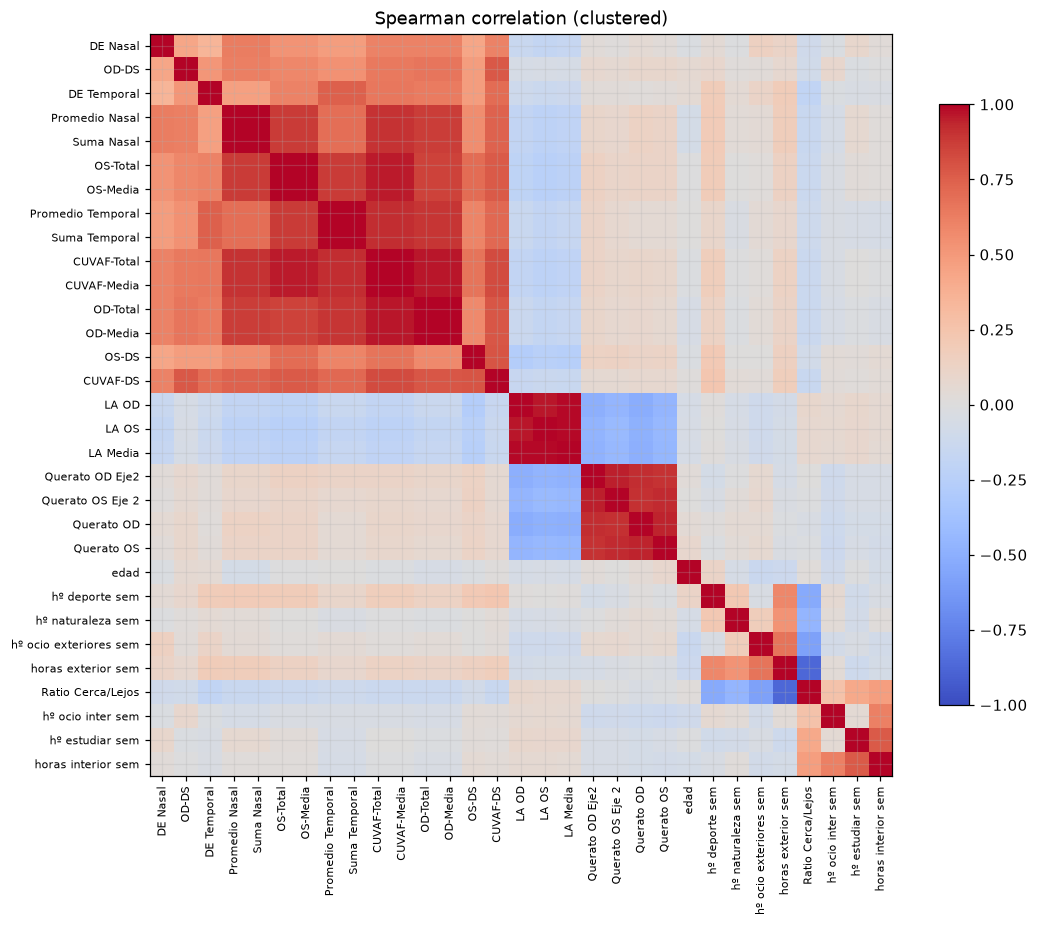

In [145]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

corr = X_t[cont_cols].corr(method='spearman')
d = (1 - corr.abs()).fillna(1).to_numpy(copy=True)   # writable copy
np.fill_diagonal(d, 0)
d = (d + d.T) / 2
order = leaves_list(linkage(squareform(d, checks=False), 'average'))
corr = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title('Spearman correlation (clustered)')
plt.tight_layout()
plt.show()

urthermore we find that the group of columns most correlated between them can also be grouped since we researched the data behind a CUVAF study. We now run the following analysis to see the difference between the columns and see if they can be aggregated into one. With this we see that CUVAF Total and CUVAF Media are the result of operating on the information in the other columns, which also happens with horas interior semana

In [146]:
rule = (Y_t['MM'] == 'SI') | (X_t[['LA OD', 'LA OS']].max(axis=1) > 26)
print('Combo MM == (MM dioptres OR axial length > 26 mm):', ((Y_t['Combo'] == 'MM') == rule).all())

def maxdiff(a, b): return float((a - b).abs().max())   # NaN-safe; ~0 means identical
print(maxdiff(X_t['CUVAF-Total'], X_t['OD-Total'] + X_t['OS-Total']))
print(maxdiff(X_t['CUVAF-Total'], X_t['Suma Nasal'] + X_t['Suma Temporal']))
print(maxdiff(X_t['CUVAF-Media'], X_t['CUVAF-Total'] / 4))
print(maxdiff(X_t['horas interior sem'], X_t['hº estudiar sem'] + X_t['hº ocio inter sem']))
print(pd.crosstab(X_t[['LA OD', 'LA OS']].max(axis=1) > 26, Y_t['Combo']))

Combo MM == (MM dioptres OR axial length > 26 mm): True
2.999999537678377e-08
4.000000330961484e-08
5.000000413701855e-09
0.0
Combo   C   M  MM
row_0            
False  44  70   3
True    0   0  15


Now we define which columns we want to keep and which we want to merge since they seem to add redundant informaiton.

Furthermore, we also define 3 scenarios to aggregate the variables and train our models. With this we can also analyze which part of the data contribute to the a better result in the learning of the algorithm

In [147]:
F = pd.DataFrame(index=X_t.index)

F['edad'] = X_t['edad']

F['mujer'] = (X_t['sexo'] == 'Mujer').astype(int)

for c in ['hº deporte sem', 'hº naturaleza sem', 'hº ocio exteriores sem', 'hº estudiar sem', 'hº ocio inter sem']:
    F[c] = X_t[c]
for new, old in [('fumador', 'fumador'), ('toma_sol', 'toma sol'), ('protege_sol', 'protege sol')]:
    F[new] = (X_t[old] == 'SI').astype(int)
F['dispositivo'] = X_t['disp.elec.antes dormir'].map({'Nunca': 0, 'A veces': 1, 'Siempre': 2})
F['fam_num'] = X_t['Familiar miope num.']
fam = X_t['familiar miope'].fillna('')
for k in ['Padre', 'Madre', 'Hermanos']:
    F[f'fam_{k.lower()}'] = fam.str.contains(k).astype(int)
F['famMM_si'] = (X_t['Familiar MM SI/NO'] == 'Si').astype(int)
F['famMM_nose'] = (X_t['Familiar MM SI/NO'] == 'No lo se').astype(int)
lifestyle = list(F.columns)

F['CUVAF_total'] = X_t['CUVAF-Total']; F['CUVAF_nasal'] = X_t['Suma Nasal']; F['CUVAF_temporal'] = X_t['Suma Temporal']
F['CUVAF_OD'] = X_t['OD-Total'];       F['CUVAF_OS'] = X_t['OS-Total']
cuvaf = ['CUVAF_total', 'CUVAF_nasal', 'CUVAF_temporal', 'CUVAF_OD', 'CUVAF_OS']

F['LA_mean'] = X_t[['LA OD', 'LA OS']].mean(axis=1)
F['LA_max'] = X_t[['LA OD', 'LA OS']].max(axis=1)
F['K_mean'] = X_t[['Querato OD', 'Querato OS']].mean(axis=1)
biometry = ['LA_mean', 'LA_max', 'K_mean']

scenarios = {'A_lifestyle': lifestyle,
             'B_+CUVAF': lifestyle + cuvaf,
             'C_+biometry': lifestyle + cuvaf + biometry}

We list the columns in our temporary dataframe F, we see that we have a much lower amount of columns

In [148]:
list(F.columns)

['edad',
 'mujer',
 'hº deporte sem',
 'hº naturaleza sem',
 'hº ocio exteriores sem',
 'hº estudiar sem',
 'hº ocio inter sem',
 'fumador',
 'toma_sol',
 'protege_sol',
 'dispositivo',
 'fam_num',
 'fam_padre',
 'fam_madre',
 'fam_hermanos',
 'famMM_si',
 'famMM_nose',
 'CUVAF_total',
 'CUVAF_nasal',
 'CUVAF_temporal',
 'CUVAF_OD',
 'CUVAF_OS',
 'LA_mean',
 'LA_max',
 'K_mean']

From the discussion in class the algorithm that most perked our interest are XGboost and SVM. Since to use these algorithms we need to define their hyperparameters we define the following functions to help better tune these hyperparameters and get a better performance out of our models

In [149]:
# =====================================================================================
# TOOL 1: make_search  ->  builds a model that can tune ITSELF (but is NOT trained yet)
# =====================================================================================
def make_search(kind, scoring, inner, seed=0):
    # kind    : 'SVM' or 'XGB' (which model to build)
    # scoring : the score the tuning tries to maximise (e.g. 'roc_auc')
    # inner   : the inner folds used to test each candidate setting
    # seed    : fixes the randomness so you get the same answer every run

    if kind == 'SVM':
        # A pipeline = an assembly line. Each station only learns from the TRAINING rows it receives,
        # so nothing leaks from the exam students.
        pipe = make_pipeline(
            SimpleImputer(strategy='median'),         # station 1: fill holes (NaN) with the column's median
            StandardScaler(),                         # station 2: put every column on the same scale
                                                      #   (an SVM measures distances; without this, "hours" would
                                                      #    shout over "axial length")
            SVC(class_weight='balanced', random_state=seed))  # station 3: the SVM; 'balanced' = mistakes on the
                                                              #   rare class cost more (matters for MM)

        # The menu of settings to try. 'svc__' = "this setting belongs to the step named svc".
        grid = [
            # Curvy boundary (rbf): 4 values of C x 4 values of gamma = 16 combinations
            #   C     = how harshly training mistakes are punished (high = memorise, low = relax)
            #   gamma = how far one student's influence reaches (small = smooth, large = wiggly)
            {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.003, 0.01, 0.03]},
            # Straight boundary (linear): 3 combinations. No gamma here, hence the separate dictionary.
            {'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1]},
        ]                                             # total: 16 + 3 = 19 candidates

        # GridSearchCV = try ALL 19 candidates on the inner folds, keep the winner, refit it on all training rows.
        return GridSearchCV(pipe, grid, scoring=scoring, cv=inner, n_jobs=1)   # n_jobs=1 -> one at a time

    # ---- otherwise: XGBoost (a team of small decision trees; each tree fixes the previous ones' mistakes) ----
    xgb = XGBClassifier(tree_method='hist',           # fast way of building trees
                        eval_metric='logloss',        # internal loss it tracks while learning
                        n_jobs=1, random_state=seed, verbosity=0)   # one core, fixed seed, no chatter

    # The menu of knobs. All combinations would be 3*3*2*2*2*2*3 = 432, far too many...
    dist = {'max_depth': [1, 2, 3],            # how many questions in a row a tree may ask (small = simple)
            'n_estimators': [50, 100, 200],    # how many trees in the team
            'learning_rate': [0.03, 0.1],      # how big a correction each new tree may make (small = cautious)
            'subsample': [0.7, 1.0],           # fraction of STUDENTS each tree sees
            'colsample_bytree': [0.5, 1.0],    # fraction of FEATURES each tree may use
            'min_child_weight': [1, 3],        # how much evidence a branch needs before it may exist
            'reg_lambda': [1, 5, 10]}          # penalty against over-confident predictions

    # ...so RandomizedSearchCV just samples 12 random combinations and tests only those.
    return RandomizedSearchCV(xgb, dist, n_iter=12, scoring=scoring, cv=inner, random_state=seed, n_jobs=1)


# =====================================================================================
# TOOL 2: get_scores  ->  one comparable "how positive is this student?" number per student
# =====================================================================================
def get_scores(search, X, K, kind):
    """binary -> 1-D score of the positive class; multiclass -> (n, K). SVM: decision_function, XGB: probability."""
    # The two models speak different languages:
    #   SVM     -> a signed DISTANCE from the boundary (positive = class 1, negative = class 0, cutoff at 0)
    #   XGBoost -> a PROBABILITY between 0 and 1 (cutoff at 0.5)
    if kind == 'SVM':
        return search.decision_function(X)        # (we avoid SVC's built-in probabilities: unstable on 132 rows)
    p = search.predict_proba(X)                   # table: one column per class
    return p[:, 1] if K == 2 else p               # 2 classes -> keep only the "positive" column; more -> keep all


# =====================================================================================
# TOOL 3: nested_cv  ->  the main routine: honest performance estimate for ONE (task, scenario, model)
# =====================================================================================
def nested_cv(y_raw, cols, kind, n_repeats=2, seed=0):
    # y_raw     : the target column (e.g. Y['M'])
    # cols      : which feature columns to use (a scenario: A, B or C)
    # kind      : 'SVM' or 'XGB'
    # n_repeats : how many times the 5-fold exam is repeated with a new shuffle (2 = quick, 5 = final run)

    # --- Prepare the data ---
    le = LabelEncoder(); y = le.fit_transform(y_raw); K = len(le.classes_)   # text labels -> 0,1,2..; K = number of classes
    Xf = F[cols].to_numpy(float)                  # pick the chosen columns from the feature table, as a plain array

    # --- The two layers of folds ---
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)   # OUTER = the real exams
    inner = StratifiedKFold(3, shuffle=True, random_state=seed)                           # INNER = practice tests for tuning

    # --- Decide what to optimise and where the yes/no cutoff is ---
    scoring = 'roc_auc' if K == 2 else 'balanced_accuracy'   # tuning target: 2 classes -> AUC, more -> balanced accuracy
    thr = 0.0 if kind == 'SVM' else 0.5                      # default cutoff: 0 for SVM distances, 0.5 for probabilities

    # --- Empty notebooks to fill in during the loop ---
    oof = np.zeros(len(y)) if K == 2 else np.zeros((len(y), K))   # "out-of-fold" scores: each student's score from an exam
                                                                  #   where they were NOT in the training set
    cnt = np.zeros(len(y))                        # how many exams each student has sat (>1 when repeats are used)
    imp = np.zeros(len(cols))                     # running total of feature importances
    rows, params = [], []                         # one row of grades per fold / the winning settings of each fold

    # --- One loop pass = one OUTER fold ---
    for tr, te in outer.split(Xf, y):             # tr = ~105 training students, te = ~27 exam students (row numbers)

        s = make_search(kind, scoring, inner, seed)           # build a fresh, untrained self-tuning model

        # TRAIN on the training students ONLY. Inside this single .fit(), the INNER loop runs:
        #   try every candidate setting on 3 inner folds -> keep the best -> refit it on all ~105 students.
        if kind == 'XGB':
            # XGBoost has no 'class_weight', so we hand it per-student weights instead (rare class = heavier)
            s.fit(Xf[tr], y[tr], sample_weight=compute_sample_weight('balanced', y[tr]))
        else:
            s.fit(Xf[tr], y[tr])

        # EXAM: score the students the model has never seen (not in training, not in tuning)
        sc = get_scores(s, Xf[te], K, kind)
        oof[te] += sc                             # store their scores (summed; averaged after the loop)
        cnt[te] += 1                              # note that these students sat one more exam
        params.append(s.best_params_)             # remember which settings won in THIS fold

        # GRADE the exam
        if K == 2:                                # two classes (M, MM)
            pred = (sc > thr).astype(int)         # score above cutoff -> class 1, otherwise class 0
            rows.append({'roc_auc': roc_auc_score(y[te], sc),               # ranking quality (uses raw scores)
                         'pr_auc': average_precision_score(y[te], sc),      # same, but focused on the positive class
                         'bal_acc': balanced_accuracy_score(y[te], pred),   # average recall of both classes
                         'f1': f1_score(y[te], pred)})                      # precision/recall balance, positive class
        else:                                     # several classes (Combo, DCombo)
            pred = sc.argmax(1)                   # choose the class with the highest score in each row
            rows.append({'bal_acc': balanced_accuracy_score(y[te], pred),
                         'f1_macro': f1_score(y[te], pred, average='macro')})   # F1 averaged over classes equally

        # WHICH FEATURES MATTERED? On the exam students only: shuffle one feature at a time (5 times each)
        # and see how much the score drops. Big drop = the model leaned on that feature.
        # (This n_repeats=5 is NOT the same 5 as the CV repeats. Don't touch it.)
        imp += permutation_importance(s.best_estimator_, Xf[te], y[te], scoring=scoring,
                                      n_repeats=5, random_state=seed).importances_mean

    # --- After the loop: tidy up ---
    oof = oof / cnt if K == 2 else oof / cnt[:, None]   # sum -> average (cnt[:, None] reshapes cnt to divide row by row)

    # --- Hand back everything in one dictionary; later cells (summary tables, plots) read from it ---
    return dict(scores=pd.DataFrame(rows),        # one row of grades per outer fold -> mean ± SD tables, boxplots
                oof=oof, y=y,                     # out-of-fold scores + true labels -> ROC/PR curves, confusion matrices
                classes=le.classes_, thr=thr,     # class names and the default cutoff
                importance=pd.Series(imp / outer.get_n_splits(), index=cols),   # importance averaged over folds
                params=params)                    # winning settings per fold -> "how stable was the tuning?"

Here we execute the hyperparameter search and the training of the model

In [150]:
tasks = {'M': (Y_t['M'], 'roc_auc'), 'MM': (Y_t['MM'], 'roc_auc'),
         'Combo': (Y_t['Combo'], 'bal_acc'), 'DCombo': (Y_t['DCombo'], 'bal_acc')}
results, t0 = {}, time.time()
for t, (yy, _) in tasks.items():
    for s, cols in scenarios.items():
        for kind in ['SVM', 'XGB']:
            results[(t, s, kind)] = nested_cv(yy, cols, kind, n_repeats=5)   # raise to 5 for the final run
            print(f'{t:7s} {s:12s} {kind}  {time.time()-t0:5.0f}s', flush=True)

summ = pd.DataFrame([{'task': t, 'scenario': s, 'model': k, 'metric': m,
                      'mean': r['scores'][m].mean(), 'std': r['scores'][m].std()}
                     for (t, s, k), r in results.items() for m in r['scores'].columns])
for t, (_, main) in tasks.items():
    d = summ[(summ.task == t) & (summ.metric == main)]
    print(f'\n{t}: {main}')
    print(d.assign(v=d['mean'].round(3).astype(str) + '±' + d['std'].round(3).astype(str))
           .pivot(index='model', columns='scenario', values='v'))

M       A_lifestyle  SVM      6s
M       A_lifestyle  XGB     14s
M       B_+CUVAF     SVM     21s
M       B_+CUVAF     XGB     29s
M       C_+biometry  SVM     35s
M       C_+biometry  XGB     44s
MM      A_lifestyle  SVM     49s
MM      A_lifestyle  XGB     56s
MM      B_+CUVAF     SVM     62s
MM      B_+CUVAF     XGB     70s
MM      C_+biometry  SVM     76s
MM      C_+biometry  XGB     84s
Combo   A_lifestyle  SVM     89s
Combo   A_lifestyle  XGB     99s
Combo   B_+CUVAF     SVM    104s
Combo   B_+CUVAF     XGB    116s
Combo   C_+biometry  SVM    121s
Combo   C_+biometry  XGB    134s
DCombo  A_lifestyle  SVM    139s
DCombo  A_lifestyle  XGB    152s
DCombo  B_+CUVAF     SVM    157s
DCombo  B_+CUVAF     XGB    172s
DCombo  C_+biometry  SVM    178s
DCombo  C_+biometry  XGB    194s

M: roc_auc
scenario  A_lifestyle     B_+CUVAF  C_+biometry
model                                          
SVM        0.63±0.096  0.642±0.118  0.835±0.102
XGB       0.664±0.086  0.614±0.118  0.825±0.094

MM:

We now plot the descriptors of our models to see what quality of predictions they make

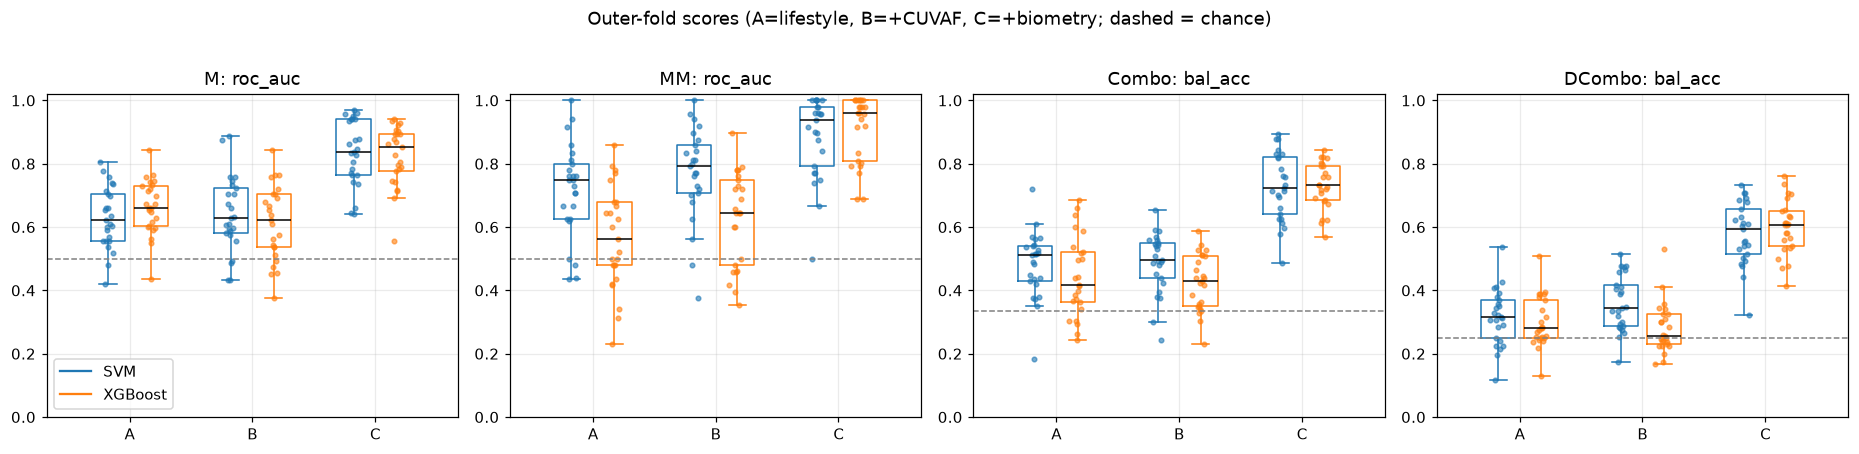

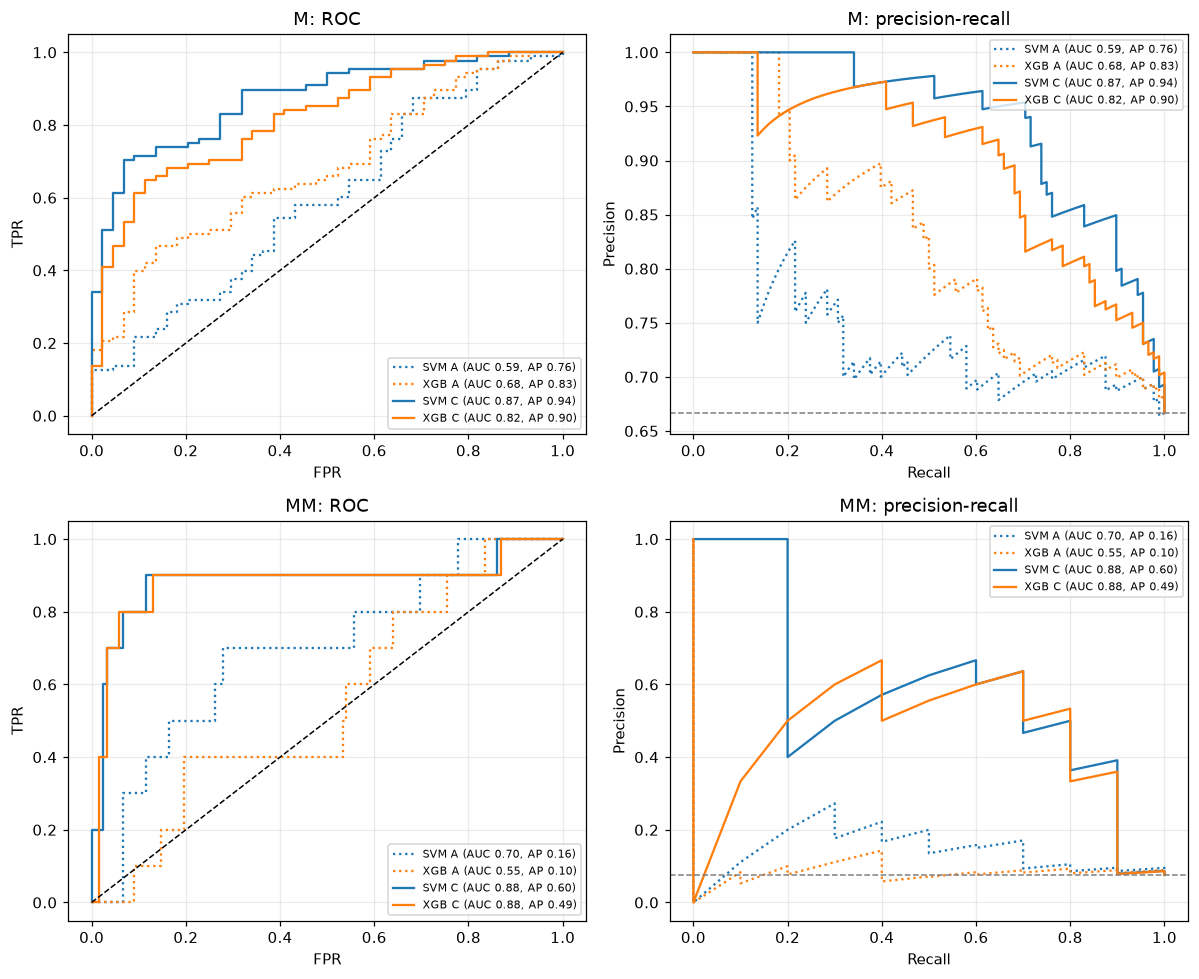

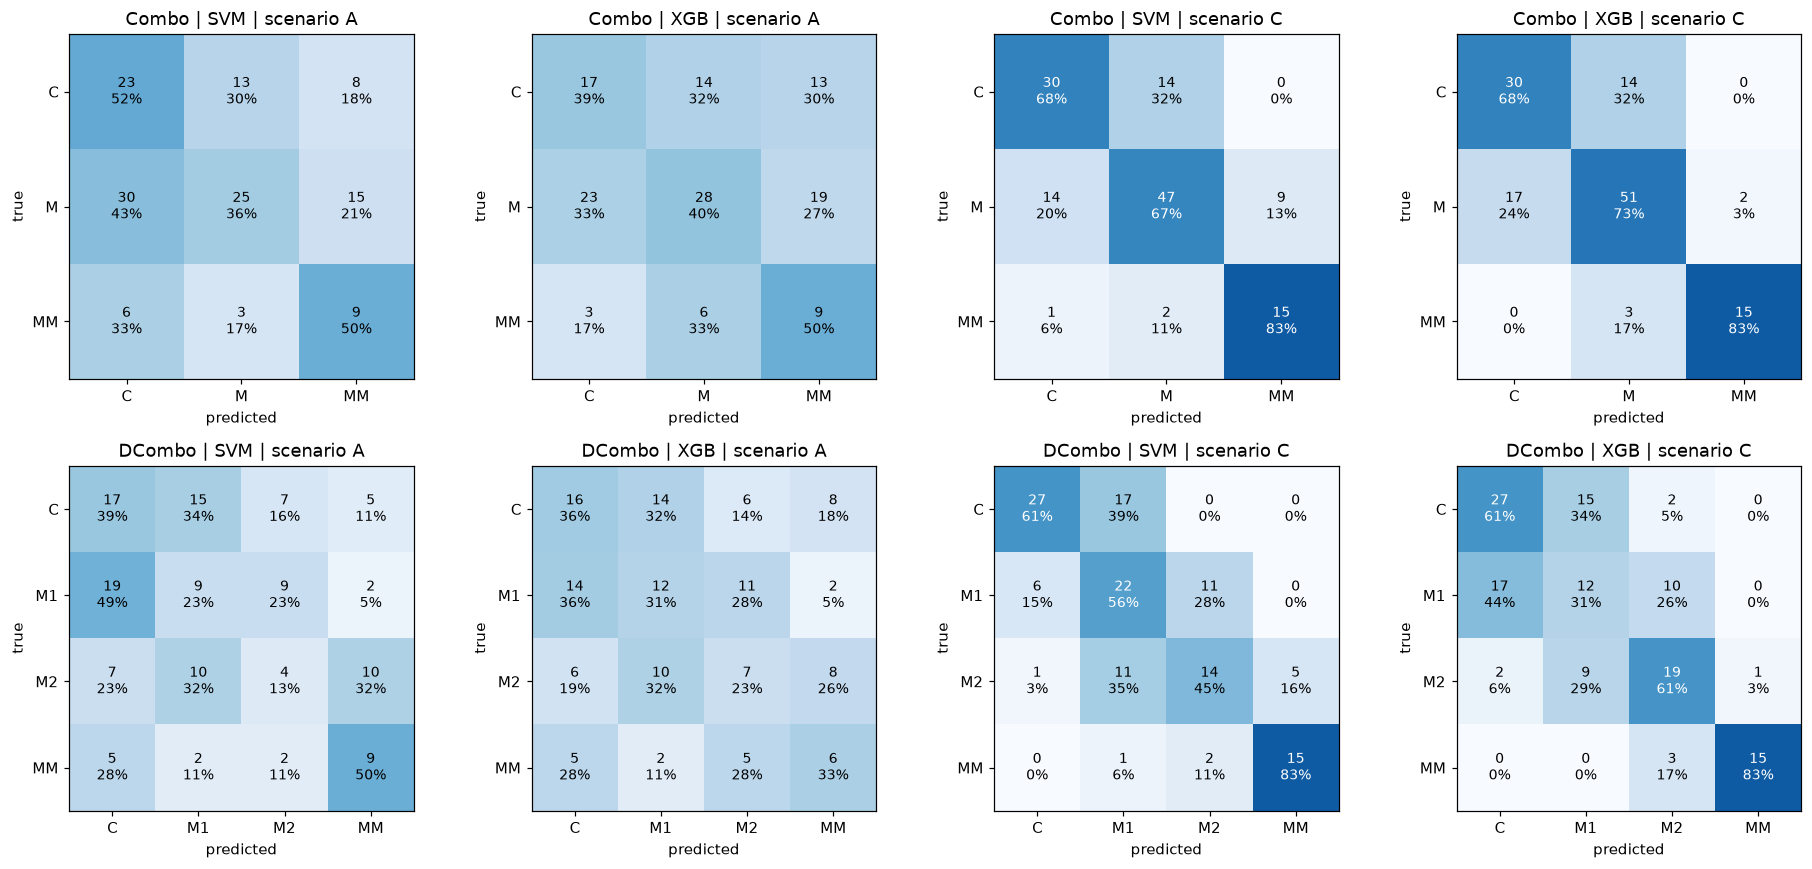

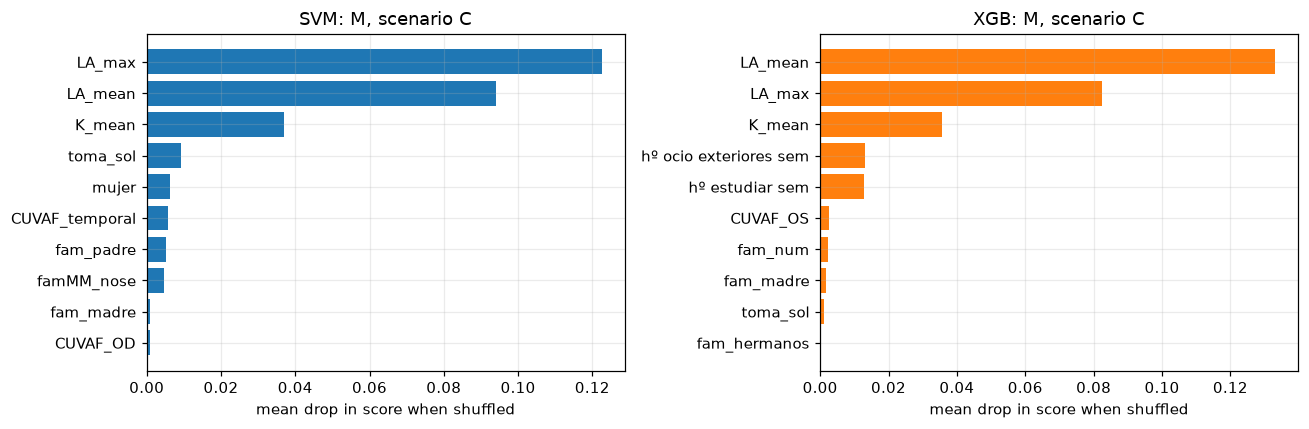

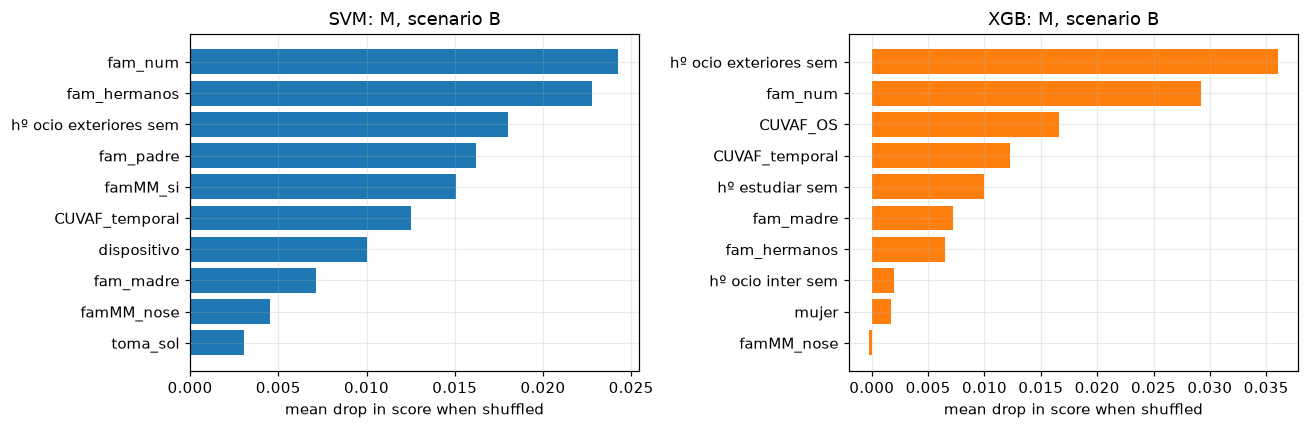

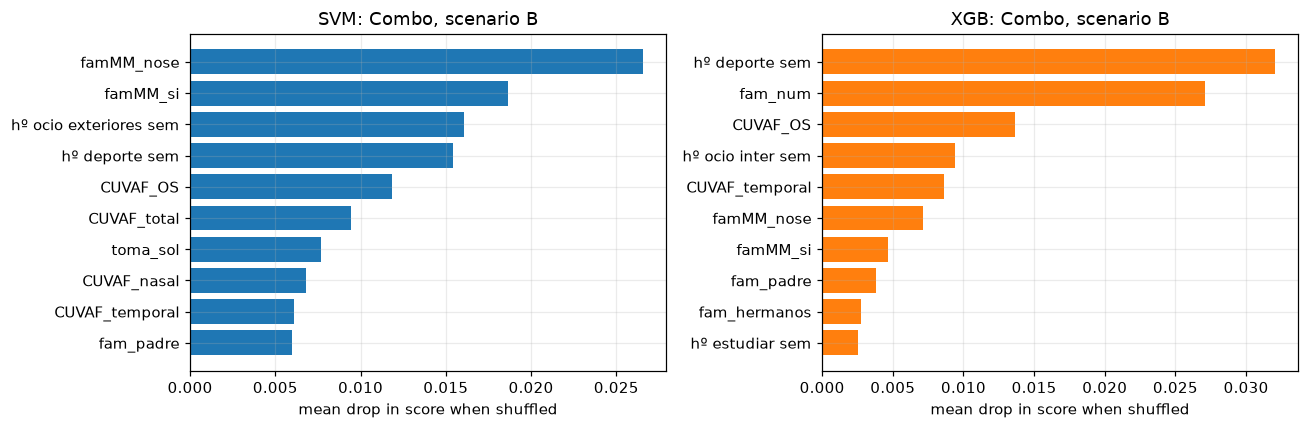

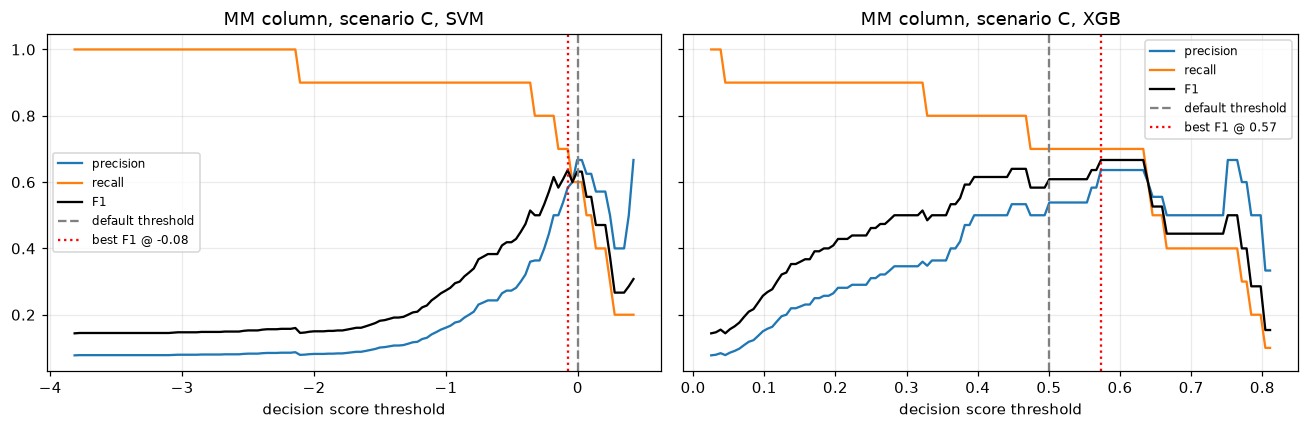


SVM, best params across outer folds (M, scenario C):
  svc__C {'100': 8, '0.01': 3, '0.1': 3, '10': 5, '1': 6}
  svc__gamma {'0.003': 8, '-': 8, '0.01': 5, '0.03': 4}
  svc__kernel {'rbf': 17, 'linear': 8}

XGB, best params across outer folds (M, scenario C):
  colsample_bytree {'0.5': 21, '1.0': 4}
  learning_rate {'0.03': 3, '0.1': 22}
  max_depth {'3': 2, '2': 20, '1': 3}
  min_child_weight {'3': 6, '1': 19}
  n_estimators {'200': 6, '100': 19}
  reg_lambda {'10': 13, '5': 7, '1': 5}
  subsample {'1.0': 8, '0.7': 17}


In [151]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
COL = {'SVM': 'tab:blue', 'XGB': 'tab:orange'}
scen_names = list(scenarios)

# ---- Plot 1: fold-level scores, SVM vs XGBoost ----
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (t, (_, main)) in zip(axes, tasks.items()):
    for i, s in enumerate(scen_names):
        for j, kind in enumerate(['SVM', 'XGB']):
            v = results[(t, s, kind)]['scores'][main].values
            pos = i + (j - .5) * .35
            ax.boxplot(v, positions=[pos], widths=.28, showfliers=False,
                       boxprops=dict(color=COL[kind]), medianprops=dict(color='k'),
                       whiskerprops=dict(color=COL[kind]), capprops=dict(color=COL[kind]))
            ax.scatter(np.random.default_rng(0).normal(pos, .03, len(v)), v, s=9, color=COL[kind], alpha=.6)
    chance = {'roc_auc': .5, 'bal_acc': 1 / len(results[(t, scen_names[0], 'SVM')]['classes'])}[main]
    ax.axhline(chance, ls='--', c='gray', lw=1)
    ax.set_xticks(range(len(scen_names))); ax.set_xticklabels([s.split('_')[0] for s in scen_names])
    ax.set_title(f'{t}: {main}'); ax.set_ylim(0, 1.02)
axes[0].plot([], [], c=COL['SVM'], label='SVM'); axes[0].plot([], [], c=COL['XGB'], label='XGBoost')
axes[0].legend(loc='lower left')
plt.suptitle('Outer-fold scores (A=lifestyle, B=+CUVAF, C=+biometry; dashed = chance)', y=1.02)
plt.tight_layout(); plt.show()

# ---- Plot 2: ROC and PR curves for M and MM (out-of-fold scores) ----
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, t in enumerate(['M', 'MM']):
    for s, ls in [('A_lifestyle', ':'), ('C_+biometry', '-')]:
        for kind in ['SVM', 'XGB']:
            R = results[(t, s, kind)]; y, p = R['y'], R['oof']
            fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
            lab = f'{kind} {s[0]} (AUC {roc_auc_score(y, p):.2f}, AP {average_precision_score(y, p):.2f})'
            axes[r, 0].plot(fpr, tpr, ls=ls, c=COL[kind], label=lab)
            axes[r, 1].plot(rc, pr, ls=ls, c=COL[kind], label=lab)
    axes[r, 0].plot([0, 1], [0, 1], 'k--', lw=1); axes[r, 0].set_title(f'{t}: ROC')
    axes[r, 0].set_xlabel('FPR'); axes[r, 0].set_ylabel('TPR')
    axes[r, 1].axhline((R['y'] == 1).mean(), c='gray', ls='--', lw=1); axes[r, 1].set_title(f'{t}: precision-recall')
    axes[r, 1].set_xlabel('Recall'); axes[r, 1].set_ylabel('Precision')
    axes[r, 0].legend(fontsize=7, loc='lower right'); axes[r, 1].legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()

# ---- Plot 3: confusion matrices for Combo and DCombo (row-normalised, counts shown) ----
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for r, t in enumerate(['Combo', 'DCombo']):
    for c, (s, kind) in enumerate([('A_lifestyle', 'SVM'), ('A_lifestyle', 'XGB'),
                                   ('C_+biometry', 'SVM'), ('C_+biometry', 'XGB')]):
        R = results[(t, s, kind)]; cm = confusion_matrix(R['y'], R['oof'].argmax(1)); norm = cm / cm.sum(1, keepdims=True)
        ax = axes[r, c]; ax.imshow(norm, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, f'{cm[i, j]}\n{norm[i, j]:.0%}', ha='center', va='center',
                        color='white' if norm[i, j] > .55 else 'black', fontsize=9)
        ax.set_xticks(range(len(R['classes']))); ax.set_xticklabels(R['classes'])
        ax.set_yticks(range(len(R['classes']))); ax.set_yticklabels(R['classes'])
        ax.set_title(f'{t} | {kind} | scenario {s[0]}'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout(); plt.show()

# ---- Plot 4: permutation importance on held-out folds (top 10) ----
def importance_plot(task, scen, topn=10):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, kind in zip(axes, ['SVM', 'XGB']):
        imp = results[(task, scen, kind)]['importance'].sort_values().tail(topn)
        ax.barh(imp.index, imp.values, color=COL[kind]); ax.set_title(f'{kind}: {task}, scenario {scen[0]}')
        ax.set_xlabel('mean drop in score when shuffled')
    plt.tight_layout(); plt.show()
importance_plot('M', 'C_+biometry'); importance_plot('M', 'B_+CUVAF'); importance_plot('Combo', 'B_+CUVAF')

# ---- Plot 5: threshold analysis for the rare MM class ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kind in zip(axes, ['SVM', 'XGB']):
    R = results[('MM', 'C_+biometry', kind)]; y, p = R['y'], R['oof']
    th = np.linspace(np.percentile(p, 2), np.percentile(p, 98), 120)
    prec = [((p >= t_) & (y == 1)).sum() / max((p >= t_).sum(), 1) for t_ in th]
    rec = [((p >= t_) & (y == 1)).sum() / (y == 1).sum() for t_ in th]
    f1 = [2 * a * b / (a + b) if a + b else 0 for a, b in zip(prec, rec)]
    ax.plot(th, prec, label='precision'); ax.plot(th, rec, label='recall'); ax.plot(th, f1, 'k', label='F1')
    ax.axvline(R['thr'], c='gray', ls='--', label='default threshold')
    ax.axvline(th[int(np.argmax(f1))], c='r', ls=':', label=f'best F1 @ {th[int(np.argmax(f1))]:.2f}')
    ax.set_title(f'MM column, scenario C, {kind}'); ax.set_xlabel('decision score threshold'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- Tuned hyperparameters: how stable are they across outer folds? ----
for kind in ['SVM', 'XGB']:
    plist = results[('M', 'C_+biometry', kind)]['params']
    print(f'\n{kind}, best params across outer folds (M, scenario C):')
    for k in sorted({k for p_ in plist for k in p_}):
        print(' ', k, dict(Counter(str(p_.get(k, '-')) for p_ in plist)))

In [152]:
def build_features(df):
    G = pd.DataFrame(index=df.index)
    G['edad'] = df['edad']
    G['mujer'] = (df['sexo'] == 'Mujer').astype(int)
    for c in ['hº deporte sem', 'hº naturaleza sem', 'hº ocio exteriores sem', 'hº estudiar sem', 'hº ocio inter sem']:
        G[c] = df[c]
    for new, old in [('fumador', 'fumador'), ('toma_sol', 'toma sol'), ('protege_sol', 'protege sol')]:
        G[new] = (df[old] == 'SI').astype(int)
    G['dispositivo'] = df['disp.elec.antes dormir'].map({'Nunca': 0, 'A veces': 1, 'Siempre': 2})
    G['fam_num'] = df['Familiar miope num.']
    fam = df['familiar miope'].fillna('')
    for k in ['Padre', 'Madre', 'Hermanos']:
        G[f'fam_{k.lower()}'] = fam.str.contains(k).astype(int)
    G['famMM_si'] = (df['Familiar MM SI/NO'] == 'Si').astype(int)
    G['famMM_nose'] = (df['Familiar MM SI/NO'] == 'No lo se').astype(int)
    G['CUVAF_total'] = df['CUVAF-Total']; G['CUVAF_nasal'] = df['Suma Nasal']; G['CUVAF_temporal'] = df['Suma Temporal']
    G['CUVAF_OD'] = df['OD-Total'];       G['CUVAF_OS'] = df['OS-Total']
    G['LA_mean'] = df[['LA OD', 'LA OS']].mean(axis=1)
    G['LA_max'] = df[['LA OD', 'LA OS']].max(axis=1)
    G['K_mean'] = df[['Querato OD', 'Querato OS']].mean(axis=1)
    return G

X_test = pd.read_csv('data/X_test.csv')
F_test = build_features(X_test)

# safety checks: the function must reproduce F exactly on train, and test must have the same columns
pd.testing.assert_frame_equal(build_features(X_t), F, check_dtype=False)
assert list(F_test.columns) == list(F.columns)
print(F_test.shape, '| NaNs per column:', F_test.isna().sum()[lambda s: s > 0].to_dict())

(24, 25) | NaNs per column: {'hº naturaleza sem': 2}


In [153]:
# Edit this dictionary with the model and scenario you decide to report for each task.
chosen = {'M':      ('SVM', 'C_+biometry'),
          'MM':     ('XGB', 'C_+biometry'),
          'Combo':  ('SVM', 'C_+biometry'),
          'DCombo': ('XGB', 'C_+biometry')}

def fit_final(y_raw, cols, kind, seed=0):
    le = LabelEncoder(); y = le.fit_transform(y_raw)
    scoring = 'roc_auc' if len(le.classes_) == 2 else 'balanced_accuracy'
    search = make_search(kind, scoring, StratifiedKFold(5, shuffle=True, random_state=seed), seed)
    Xf = F[cols].to_numpy(float)
    if kind == 'XGB': search.fit(Xf, y, sample_weight=compute_sample_weight('balanced', y))
    else:             search.fit(Xf, y)
    print(f'  best CV score {search.best_score_:.3f} | {search.best_params_}')
    return search, le

preds = pd.DataFrame(index=X_test.index)
for task, (kind, scen) in chosen.items():
    print(task, kind, scen)
    cols = scenarios[scen]
    search, le = fit_final(Y_t[task], cols, kind)
    preds[task] = le.inverse_transform(search.predict(F_test[cols].to_numpy(float)))

M SVM C_+biometry
  best CV score 0.906 | {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
MM XGB C_+biometry
  best CV score 0.934 | {'subsample': 1.0, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Combo SVM C_+biometry
  best CV score 0.752 | {'svc__C': 10, 'svc__gamma': 0.003, 'svc__kernel': 'rbf'}
DCombo XGB C_+biometry
  best CV score 0.631 | {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 1, 'learning_rate': 0.03, 'colsample_bytree': 0.5}


In [154]:
bad = {
    'M=NO but Combo is M/MM':   ((preds['M'] == 'NO') & (preds['Combo'] != 'C')).sum(),
    'M=SI but Combo=C':         ((preds['M'] == 'SI') & (preds['Combo'] == 'C')).sum(),
    'MM=SI but Combo!=MM':      ((preds['MM'] == 'SI') & (preds['Combo'] != 'MM')).sum(),
    'Combo vs DCombo disagree': (preds['Combo'] != preds['DCombo'].replace({'M1': 'M', 'M2': 'M'})).sum(),
}
print('Contradictions between tasks:', bad)

Contradictions between tasks: {'M=NO but Combo is M/MM': np.int64(1), 'M=SI but Combo=C': np.int64(1), 'MM=SI but Combo!=MM': np.int64(1), 'Combo vs DCombo disagree': np.int64(8)}


In [155]:
cols = scenarios['C_+biometry']
myopes = Y_t['DCombo'].isin(['M1', 'M2'])
le12 = LabelEncoder(); y12 = le12.fit_transform(Y_t.loc[myopes, 'DCombo'])
search12 = make_search('SVM', 'roc_auc', StratifiedKFold(5, shuffle=True, random_state=0))
search12.fit(F.loc[myopes, cols].to_numpy(float), y12)

final = pd.DataFrame(index=X_test.index)
final['Combo'] = preds['Combo']
final['M'] = np.where(final['Combo'] == 'C', 'NO', 'SI')
final['MM'] = np.where((preds['MM'] == 'SI') & (final['Combo'] == 'MM'), 'SI', 'NO')   # SI only if both models agree
final['DCombo'] = final['Combo']                       # C and MM carry over unchanged
is_m = final['Combo'] == 'M'
if is_m.any():
    final.loc[is_m, 'DCombo'] = le12.inverse_transform(search12.predict(F_test.loc[is_m, cols].to_numpy(float)))
final = final[['M', 'MM', 'Combo', 'DCombo']]

final = final[list(Y_t.columns)]                  # same column names and order as the training labels: M, MM, Combo, DCombo
assert len(final) == len(X_test)                # one row per test student
assert list(final.index) == list(X_test.index)  # same row order as X_test (no sorting happened)

final.to_csv('predictions_test.csv', index=False)
print(pd.read_csv('predictions_test.csv').head())

    M  MM Combo DCombo
0  SI  SI    MM     MM
1  NO  NO     C      C
2  SI  SI    MM     MM
3  SI  NO     M     M1
4  SI  NO     M     M1
